# Initial EDA: CEEW Smart-Meter Electricity Consumption Data

Primary dataset: `SM Cleaned Data MH2021.csv`

This notebook performs an initial exploratory data analysis without modifying the original CSV. It loads the source file from its existing workspace location, checks schema and data quality, calculates descriptive statistics and zero-reading percentages, and creates the requested visualizations.

## 1. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", "{:.6f}".format)

DATA_FILENAME = "SM Cleaned Data MH2021.csv"

def find_project_root(start: Path) -> Path | None:
    """Find a project root containing the expected data layout."""
    for candidate in [start, *start.parents]:
        if (candidate / "dataverse_files" / DATA_FILENAME).exists() or (candidate / "data" / DATA_FILENAME).exists():
            return candidate
    return None

PROJECT_ROOT = find_project_root(Path.cwd())

candidate_paths = []
if PROJECT_ROOT is not None:
    candidate_paths.extend([
        PROJECT_ROOT / "data" / DATA_FILENAME,
        PROJECT_ROOT / "dataverse_files" / DATA_FILENAME,
    ])

# Final fallback for this local workspace. The file is only read; it is not moved or duplicated.
candidate_paths.append(Path(r"E:\MLOPS PROJECT\dataverse_files\SM Cleaned Data MH2021.csv"))

DATA_PATH = next((path for path in candidate_paths if path.exists()), None)
if DATA_PATH is None:
    searched = "\n".join(str(path) for path in candidate_paths)
    raise FileNotFoundError(
        "Could not find SM Cleaned Data MH2021.csv. "
        "Place it under data/ or dataverse_files/ at the project root, or update DATA_PATH.\n"
        f"Searched:\n{searched}"
    )

if PROJECT_ROOT is None:
    PROJECT_ROOT = DATA_PATH.parents[1]

try:
    DATA_PATH_DISPLAY = DATA_PATH.relative_to(PROJECT_ROOT)
except ValueError:
    DATA_PATH_DISPLAY = DATA_PATH

print(f"Project root: {PROJECT_ROOT}")
print(f"Dataset path: {DATA_PATH_DISPLAY}")
DATA_PATH

Project root: E:\MLOPS PROJECT
Dataset path: dataverse_files\SM Cleaned Data MH2021.csv


WindowsPath('E:/MLOPS PROJECT/dataverse_files/SM Cleaned Data MH2021.csv')

## 2. Load Data

In [2]:
df = pd.read_csv(DATA_PATH)
raw_shape = df.shape
raw_columns = df.columns.tolist()
raw_dtypes = df.dtypes

print(f"Loaded: {DATA_PATH}")
print(f"Shape: {raw_shape[0]:,} rows x {raw_shape[1]:,} columns")

Loaded: E:\MLOPS PROJECT\dataverse_files\SM Cleaned Data MH2021.csv
Shape: 550,560 rows x 6 columns


## 3. First Rows, Shape, Columns, and Data Types

In [3]:
display(df.head())
print("Shape:", df.shape)
print("Columns:")
for column in df.columns:
    print(f"- {column}")

display(df.dtypes.to_frame("dtype"))

,x_Timestamp,t_kWh,z_Avg Voltage (Volt),z_Avg Current (Amp),y_Freq (Hz),meter
0,2021-01-02 00:00:00,0.000000,0.000000,0.000000,0.000000,MH01
1,2021-01-02 00:03:00,0.000000,0.000000,0.000000,0.000000,MH01
2,2021-01-02 00:06:00,0.000000,0.000000,0.000000,0.000000,MH01
3,2021-01-02 00:09:00,0.000000,0.000000,0.000000,0.000000,MH01
4,2021-01-02 00:12:00,0.000000,0.000000,0.000000,0.000000,MH01


Shape: (550560, 6)
Columns:
- x_Timestamp
- t_kWh
- z_Avg Voltage (Volt)
- z_Avg Current (Amp)
- y_Freq (Hz)
- meter


,dtype
x_Timestamp,object
t_kWh,float64
z_Avg Voltage (Volt),float64
z_Avg Current (Amp),float64
y_Freq (Hz),float64
meter,object


## 4. Timestamp Conversion

In [4]:
timestamp_column = "x_Timestamp"
if timestamp_column not in df.columns:
    raise KeyError(f"Expected timestamp column {timestamp_column!r} was not found.")

df[timestamp_column] = pd.to_datetime(df[timestamp_column], errors="coerce")
invalid_timestamps = int(df[timestamp_column].isna().sum())

print(f"Invalid/unparseable timestamps: {invalid_timestamps:,}")
print(f"Time range: {df[timestamp_column].min()} to {df[timestamp_column].max()}")
display(df[[timestamp_column]].head())

Invalid/unparseable timestamps: 0
Time range: 2021-01-01 00:00:00 to 2021-02-20 23:57:00


,x_Timestamp
0,2021-01-02 00:00:00
1,2021-01-02 00:03:00
2,2021-01-02 00:06:00
3,2021-01-02 00:09:00
4,2021-01-02 00:12:00


## 5. Missing Values and Duplicate Rows

In [5]:
missing_values = df.isna().sum().sort_values(ascending=False)
duplicate_rows = int(df.duplicated().sum())

missing_summary = pd.DataFrame({
    "missing_count": missing_values,
    "missing_percent": (missing_values / len(df) * 100).round(4),
})

display(missing_summary)
print(f"Duplicate rows: {duplicate_rows:,}")

,missing_count,missing_percent
x_Timestamp,0,0.000000
t_kWh,0,0.000000
z_Avg Voltage (Volt),0,0.000000
z_Avg Current (Amp),0,0.000000
y_Freq (Hz),0,0.000000
meter,0,0.000000


Duplicate rows: 0


## 6. Descriptive Statistics

In [6]:
numeric_columns = df.select_dtypes(include=[np.number]).columns.tolist()
print("Numeric columns:", numeric_columns)

descriptive_stats = df[numeric_columns].describe().T if numeric_columns else pd.DataFrame()
display(descriptive_stats)

Numeric columns: ['t_kWh', 'z_Avg Voltage (Volt)', 'z_Avg Current (Amp)', 'y_Freq (Hz)']


,count,mean,std,min,25%,50%,75%,max
t_kWh,550560.000000,0.006852,0.013761,0.000000,0.001000,0.003000,0.008000,0.232000
z_Avg Voltage (Volt),550560.000000,223.719934,83.854298,0.000000,242.650000,253.890000,261.570000,654.730000
z_Avg Current (Amp),550560.000000,0.708009,1.192096,0.000000,0.090000,0.370000,0.890000,18.290000
y_Freq (Hz),550560.000000,43.955283,16.305434,0.000000,49.940000,50.000000,50.040000,74.760000


## 7. Zero Reading Percentages

In [7]:
if numeric_columns:
    zero_reading_percent = (
        df[numeric_columns].eq(0).sum()
        .div(len(df))
        .mul(100)
        .sort_values(ascending=False)
        .to_frame("zero_percent")
    )
else:
    zero_reading_percent = pd.DataFrame(columns=["zero_percent"])

display(zero_reading_percent)

,zero_percent
t_kWh,20.792647
z_Avg Current (Amp),14.452921
z_Avg Voltage (Volt),12.095866
y_Freq (Hz),12.095866


## 8. Distribution of Household Energy Consumption (`t_kWh`)

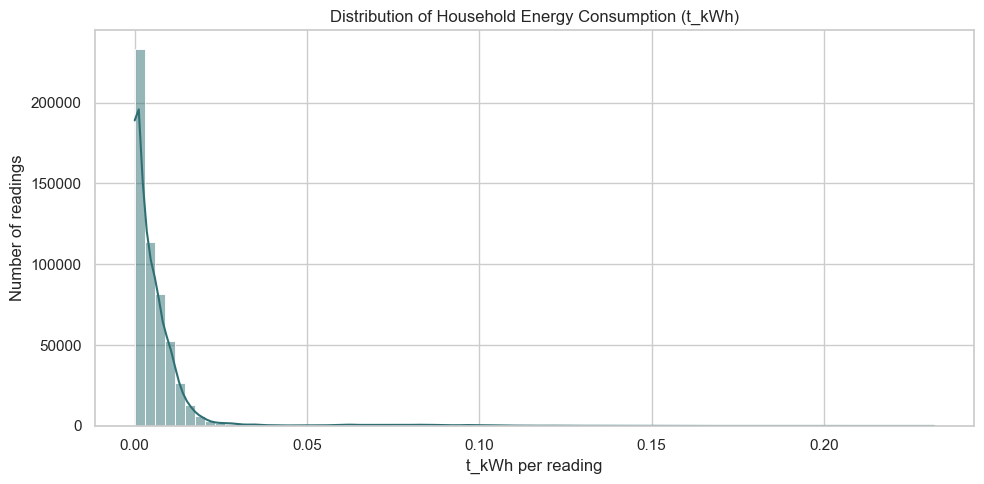

,t_kWh
0.000000,0.000000
0.250000,0.001000
0.500000,0.003000
0.750000,0.008000
0.900000,0.013000
0.950000,0.018000
0.990000,0.085000
1.000000,0.232000


In [8]:
consumption_column = "t_kWh"
if consumption_column not in df.columns:
    raise KeyError(f"Expected consumption column {consumption_column!r} was not found.")

plt.figure(figsize=(10, 5))
sns.histplot(df[consumption_column], bins=80, kde=True, color="#2f6f73")
plt.title("Distribution of Household Energy Consumption (t_kWh)")
plt.xlabel("t_kWh per reading")
plt.ylabel("Number of readings")
plt.tight_layout()
plt.show()

consumption_quantiles = df[consumption_column].quantile([0, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 1.0])
display(consumption_quantiles.to_frame("t_kWh"))

## 9. Energy Consumption Over Time

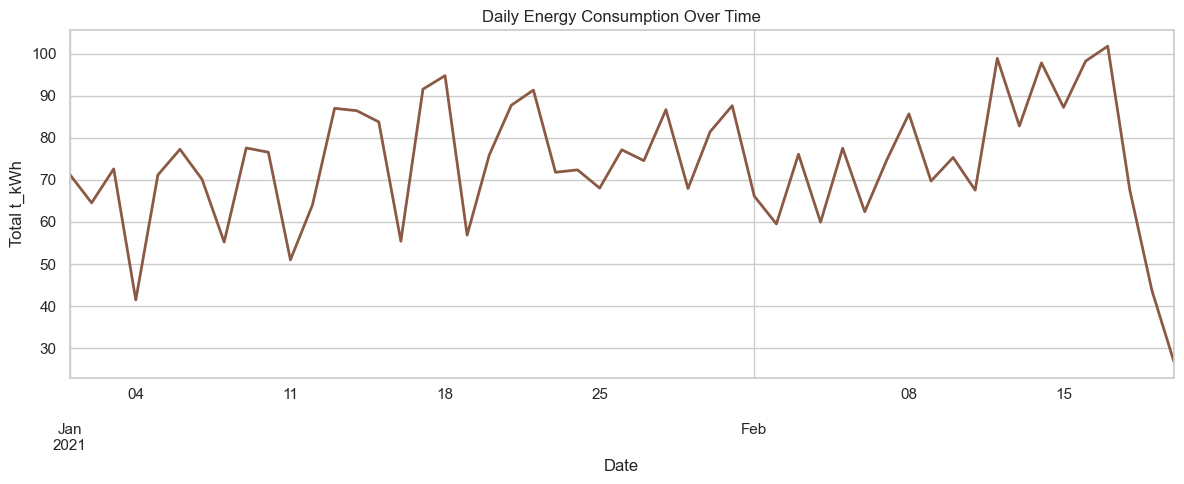

,daily_t_kWh
count,51.000000
mean,73.969000
std,15.368595
min,26.712000
25%,66.861000
50%,74.791000
75%,86.117500
max,101.837000


In [9]:
daily_consumption = (
    df.set_index(timestamp_column)[consumption_column]
    .resample("D")
    .sum()
)

plt.figure(figsize=(12, 5))
daily_consumption.plot(color="#8a5a44", linewidth=2)
plt.title("Daily Energy Consumption Over Time")
plt.xlabel("Date")
plt.ylabel("Total t_kWh")
plt.tight_layout()
plt.show()

display(daily_consumption.describe().to_frame("daily_t_kWh"))

## 10. Correlation Heatmap for Numeric Measurements

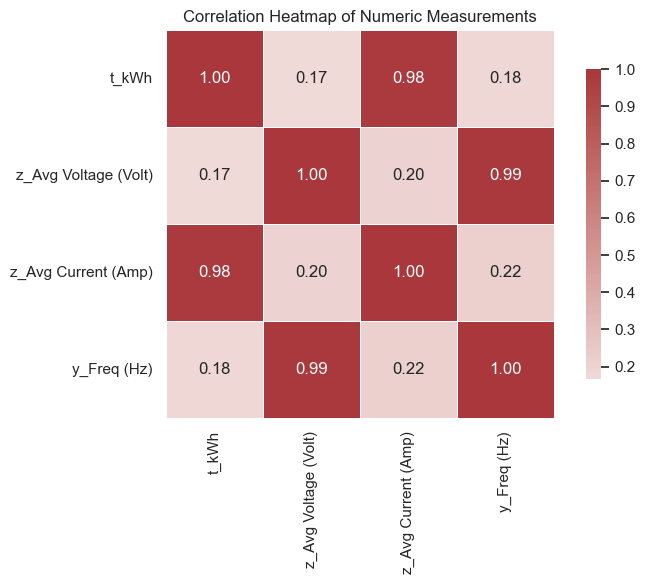

,t_kWh,z_Avg Voltage (Volt),z_Avg Current (Amp),y_Freq (Hz)
t_kWh,1.000000,0.165934,0.976062,0.184734
z_Avg Voltage (Volt),0.165934,1.000000,0.202148,0.989654
z_Avg Current (Amp),0.976062,0.202148,1.000000,0.220338
y_Freq (Hz),0.184734,0.989654,0.220338,1.000000


In [10]:
if len(numeric_columns) >= 2:
    correlation_matrix = df[numeric_columns].corr()
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        correlation_matrix,
        annot=True,
        fmt=".2f",
        cmap="vlag",
        center=0,
        square=True,
        linewidths=0.5,
        cbar_kws={"shrink": 0.8},
    )
    plt.title("Correlation Heatmap of Numeric Measurements")
    plt.tight_layout()
    plt.show()
    display(correlation_matrix)
else:
    print("Correlation heatmap skipped: fewer than two numeric columns are available.")

## 11. Compact EDA Summary Objects

In [11]:
eda_summary = {
    "dataset_path": str(DATA_PATH),
    "raw_shape": raw_shape,
    "columns": raw_columns,
    "raw_dtypes": raw_dtypes.astype(str).to_dict(),
    "invalid_timestamps": invalid_timestamps,
    "time_min": df[timestamp_column].min(),
    "time_max": df[timestamp_column].max(),
    "missing_values": missing_values.to_dict(),
    "duplicate_rows": duplicate_rows,
    "numeric_columns": numeric_columns,
    "zero_reading_percent": zero_reading_percent["zero_percent"].round(4).to_dict(),
}

eda_summary

{'dataset_path': 'E:\\MLOPS PROJECT\\dataverse_files\\SM Cleaned Data MH2021.csv',
 'raw_shape': (550560, 6),
 'columns': ['x_Timestamp',
  't_kWh',
  'z_Avg Voltage (Volt)',
  'z_Avg Current (Amp)',
  'y_Freq (Hz)',
  'meter'],
 'raw_dtypes': {'x_Timestamp': 'object',
  't_kWh': 'float64',
  'z_Avg Voltage (Volt)': 'float64',
  'z_Avg Current (Amp)': 'float64',
  'y_Freq (Hz)': 'float64',
  'meter': 'object'},
 'invalid_timestamps': 0,
 'time_min': Timestamp('2021-01-01 00:00:00'),
 'time_max': Timestamp('2021-02-20 23:57:00'),
 'missing_values': {'x_Timestamp': 0,
  't_kWh': 0,
  'z_Avg Voltage (Volt)': 0,
  'z_Avg Current (Amp)': 0,
  'y_Freq (Hz)': 0,
  'meter': 0},
 'duplicate_rows': 0,
 'numeric_columns': ['t_kWh',
  'z_Avg Voltage (Volt)',
  'z_Avg Current (Amp)',
  'y_Freq (Hz)'],
 'zero_reading_percent': {'t_kWh': 20.7926,
  'z_Avg Current (Amp)': 14.4529,
  'z_Avg Voltage (Volt)': 12.0959,
  'y_Freq (Hz)': 12.0959}}

## 12. Meter-Level Data Integrity Checks

These checks look within each meter's own timestamp sequence. They do not assume all meters have identical start/end dates or complete coverage; the observed coverage is reported explicitly.

### 12.1 Duplicate `(meter, x_Timestamp)` Combinations

In [12]:
key_columns = ["meter", timestamp_column]
missing_key_columns = [column for column in key_columns if column not in df.columns]
if missing_key_columns:
    raise KeyError(f"Missing required key columns: {missing_key_columns}")

duplicate_meter_timestamp_mask = df.duplicated(key_columns, keep=False)
duplicate_meter_timestamp_rows = int(duplicate_meter_timestamp_mask.sum())
duplicate_meter_timestamp_pairs = (
    df.loc[duplicate_meter_timestamp_mask, key_columns]
    .drop_duplicates()
    .sort_values(key_columns)
)

print(f"Duplicate rows by (meter, x_Timestamp): {duplicate_meter_timestamp_rows:,}")
print(f"Duplicate (meter, x_Timestamp) pairs: {len(duplicate_meter_timestamp_pairs):,}")
if duplicate_meter_timestamp_rows:
    display(df.loc[duplicate_meter_timestamp_mask].sort_values(key_columns).head(20))
else:
    print("No duplicate meter-timestamp combinations found.")

Duplicate rows by (meter, x_Timestamp): 0
Duplicate (meter, x_Timestamp) pairs: 0
No duplicate meter-timestamp combinations found.


### 12.2 Timestamp Coverage and Gaps by Meter

In [13]:
expected_interval = pd.Timedelta(minutes=3)

meter_sorted = df.sort_values(["meter", timestamp_column]).copy()
meter_sorted["timestamp_gap"] = meter_sorted.groupby("meter")[timestamp_column].diff()

large_gap_rows = meter_sorted[meter_sorted["timestamp_gap"] > expected_interval].copy()
large_gap_summary = (
    large_gap_rows.groupby("meter")
    .agg(
        gaps_gt_3min=("timestamp_gap", "size"),
        largest_gap=("timestamp_gap", "max"),
        first_large_gap_at=(timestamp_column, "min"),
    )
    .reset_index()
)

meter_coverage = (
    meter_sorted.groupby("meter")
    .agg(
        record_count=(timestamp_column, "size"),
        first_timestamp=(timestamp_column, "min"),
        last_timestamp=(timestamp_column, "max"),
    )
    .reset_index()
)
meter_coverage = meter_coverage.merge(large_gap_summary, on="meter", how="left")
meter_coverage["gaps_gt_3min"] = meter_coverage["gaps_gt_3min"].fillna(0).astype(int)
meter_coverage["largest_gap"] = meter_coverage["largest_gap"].fillna(pd.Timedelta(0))
meter_coverage["coverage_days"] = (
    meter_coverage["last_timestamp"] - meter_coverage["first_timestamp"]
).dt.total_seconds() / 86400
meter_coverage["expected_slots_if_continuous_within_own_range"] = (
    meter_coverage["coverage_days"] * 24 * 60 / 3 + 1
).round().astype(int)
meter_coverage["missing_slots_vs_own_observed_range"] = (
    meter_coverage["expected_slots_if_continuous_within_own_range"] - meter_coverage["record_count"]
)

print(f"Meters checked: {meter_coverage['meter'].nunique():,}")
print(f"Meters with gaps > 3 minutes: {(meter_coverage['gaps_gt_3min'] > 0).sum():,}")
print(f"Total gaps > 3 minutes: {meter_coverage['gaps_gt_3min'].sum():,}")
print(f"Largest gap: {meter_coverage['largest_gap'].max()}")

display(
    meter_coverage.sort_values(["gaps_gt_3min", "largest_gap"], ascending=False)
    .head(15)
)

display(
    meter_coverage[["meter", "record_count", "first_timestamp", "last_timestamp", "coverage_days"]]
    .sort_values("record_count")
    .head(10)
)

Meters checked: 35
Meters with gaps > 3 minutes: 35
Total gaps > 3 minutes: 261
Largest gap: 29 days 00:03:00


,meter,record_count,first_timestamp,last_timestamp,gaps_gt_3min,largest_gap,first_large_gap_at,coverage_days,expected_slots_if_continuous_within_own_range,missing_slots_vs_own_observed_range
34,MH47,12000,2021-01-01,2021-02-18 23:57:00,14,5 days 00:03:00,2021-01-07,48.997917,23520,11520
3,MH07,14880,2021-01-01,2021-02-18 23:57:00,14,3 days 00:03:00,2021-01-06,48.997917,23520,8640
19,MH27,10560,2021-01-06,2021-02-17 23:57:00,14,3 days 00:03:00,2021-01-09,42.997917,20640,10080
22,MH31,12480,2021-01-05,2021-02-18 23:57:00,14,2 days 00:03:00,2021-01-09,44.997917,21600,9120
16,MH24,11520,2021-01-03,2021-02-19 23:57:00,13,6 days 00:03:00,2021-01-05,47.997917,23040,11520
24,MH34,7200,2021-01-01,2021-02-19 23:57:00,12,8 days 00:03:00,2021-01-03,49.997917,24000,16800
10,MH17,11040,2021-01-01,2021-02-18 23:57:00,12,4 days 00:03:00,2021-01-06,48.997917,23520,12480
2,MH06,14880,2021-01-01,2021-02-18 23:57:00,12,2 days 00:03:00,2021-01-06,48.997917,23520,8640
11,MH18,13920,2021-01-05,2021-02-20 23:57:00,11,5 days 00:03:00,2021-01-08,46.997917,22560,8640
14,MH22,9600,2021-01-03,2021-02-17 23:57:00,11,4 days 00:03:00,2021-01-07,45.997917,22080,12480


,meter,record_count,first_timestamp,last_timestamp,coverage_days
25,MH35,6240,2021-01-18,2021-02-17 23:57:00,30.997917
28,MH39,6240,2021-01-07,2021-02-19 23:57:00,43.997917
23,MH33,6720,2021-01-09,2021-02-16 23:57:00,38.997917
29,MH41,7200,2021-01-01,2021-02-20 23:57:00,50.997917
24,MH34,7200,2021-01-01,2021-02-19 23:57:00,49.997917
18,MH26,8160,2021-01-01,2021-02-18 23:57:00,48.997917
14,MH22,9600,2021-01-03,2021-02-17 23:57:00,45.997917
12,MH20,10080,2021-01-01,2021-02-17 23:57:00,47.997917
19,MH27,10560,2021-01-06,2021-02-17 23:57:00,42.997917
10,MH17,11040,2021-01-01,2021-02-18 23:57:00,48.997917


### 12.3 Consecutive Zero-Reading Runs by Meter

In [14]:
def longest_zero_runs_by_meter(frame: pd.DataFrame, value_column: str) -> pd.DataFrame:
    cols = ["meter", timestamp_column, value_column]
    work = frame[cols].sort_values(["meter", timestamp_column]).copy()
    work["is_zero"] = work[value_column].eq(0)
    work["zero_run_id"] = work.groupby("meter")["is_zero"].transform(lambda s: s.ne(s.shift()).cumsum())

    runs = (
        work[work["is_zero"]]
        .groupby(["meter", "zero_run_id"])
        .agg(
            run_length_records=("is_zero", "size"),
            start_timestamp=(timestamp_column, "min"),
            end_timestamp=(timestamp_column, "max"),
        )
        .reset_index()
    )
    if runs.empty:
        return pd.DataFrame(
            columns=["meter", "run_length_records", "start_timestamp", "end_timestamp", "duration_minutes"]
        )

    runs["duration_minutes"] = runs["run_length_records"] * 3
    longest_idx = runs.groupby("meter")["run_length_records"].idxmax()
    return (
        runs.loc[longest_idx, ["meter", "run_length_records", "start_timestamp", "end_timestamp", "duration_minutes"]]
        .sort_values("run_length_records", ascending=False)
        .reset_index(drop=True)
    )

zero_run_columns = ["t_kWh", "z_Avg Voltage (Volt)", "y_Freq (Hz)"]
zero_run_summaries = {
    column: longest_zero_runs_by_meter(df, column)
    for column in zero_run_columns
}

for column, summary in zero_run_summaries.items():
    print(f"Longest zero-reading runs by meter for {column}:")
    display(summary.head(10))

Longest zero-reading runs by meter for t_kWh:


,meter,run_length_records,start_timestamp,end_timestamp,duration_minutes
0,MH28,457,2021-01-12 19:12:00,2021-01-13 18:00:00,1371
1,MH24,237,2021-02-17 16:18:00,2021-02-19 04:06:00,711
2,MH33,236,2021-01-24 16:12:00,2021-01-25 03:57:00,708
3,MH18,230,2021-01-20 17:24:00,2021-01-22 04:51:00,690
4,MH07,225,2021-01-24 16:54:00,2021-01-26 04:06:00,675
5,MH30,225,2021-02-16 19:24:00,2021-02-17 06:36:00,675
6,MH01,221,2021-01-13 17:00:00,2021-01-14 04:00:00,663
7,MH08,212,2021-01-25 17:30:00,2021-01-26 04:03:00,636
8,MH20,202,2021-01-08 18:12:00,2021-01-17 04:15:00,606
9,MH34,202,2021-01-25 18:48:00,2021-02-03 04:51:00,606


Longest zero-reading runs by meter for z_Avg Voltage (Volt):


,meter,run_length_records,start_timestamp,end_timestamp,duration_minutes
0,MH24,237,2021-02-17 16:18:00,2021-02-19 04:06:00,711
1,MH33,236,2021-01-24 16:12:00,2021-01-25 03:57:00,708
2,MH18,230,2021-01-20 17:24:00,2021-01-22 04:51:00,690
3,MH07,225,2021-01-24 16:54:00,2021-01-26 04:06:00,675
4,MH01,221,2021-01-13 17:00:00,2021-01-14 04:00:00,663
5,MH08,212,2021-01-25 17:30:00,2021-01-26 04:03:00,636
6,MH34,202,2021-01-25 18:48:00,2021-02-03 04:51:00,606
7,MH06,201,2021-02-09 16:54:00,2021-02-10 02:54:00,603
8,MH20,199,2021-01-08 18:15:00,2021-01-17 04:09:00,597
9,MH26,194,2021-02-10 16:09:00,2021-02-13 01:48:00,582


Longest zero-reading runs by meter for y_Freq (Hz):


,meter,run_length_records,start_timestamp,end_timestamp,duration_minutes
0,MH24,237,2021-02-17 16:18:00,2021-02-19 04:06:00,711
1,MH33,236,2021-01-24 16:12:00,2021-01-25 03:57:00,708
2,MH18,230,2021-01-20 17:24:00,2021-01-22 04:51:00,690
3,MH07,225,2021-01-24 16:54:00,2021-01-26 04:06:00,675
4,MH01,221,2021-01-13 17:00:00,2021-01-14 04:00:00,663
5,MH08,212,2021-01-25 17:30:00,2021-01-26 04:03:00,636
6,MH34,202,2021-01-25 18:48:00,2021-02-03 04:51:00,606
7,MH06,201,2021-02-09 16:54:00,2021-02-10 02:54:00,603
8,MH20,199,2021-01-08 18:15:00,2021-01-17 04:09:00,597
9,MH26,194,2021-02-10 16:09:00,2021-02-13 01:48:00,582


### 12.4 Zero Voltage, Zero Frequency, and Zero Consumption Overlap

In [15]:
zero_voltage = df["z_Avg Voltage (Volt)"].eq(0)
zero_frequency = df["y_Freq (Hz)"].eq(0)
zero_consumption = df["t_kWh"].eq(0)

zero_overlap_summary = pd.DataFrame([
    {
        "condition": "zero_voltage",
        "records": int(zero_voltage.sum()),
        "percent_of_dataset": zero_voltage.mean() * 100,
        "zero_consumption_records": int((zero_voltage & zero_consumption).sum()),
        "zero_consumption_percent_within_condition": (zero_voltage & zero_consumption).sum() / zero_voltage.sum() * 100,
    },
    {
        "condition": "zero_frequency",
        "records": int(zero_frequency.sum()),
        "percent_of_dataset": zero_frequency.mean() * 100,
        "zero_consumption_records": int((zero_frequency & zero_consumption).sum()),
        "zero_consumption_percent_within_condition": (zero_frequency & zero_consumption).sum() / zero_frequency.sum() * 100,
    },
    {
        "condition": "zero_voltage_and_zero_frequency",
        "records": int((zero_voltage & zero_frequency).sum()),
        "percent_of_dataset": (zero_voltage & zero_frequency).mean() * 100,
        "zero_consumption_records": int((zero_voltage & zero_frequency & zero_consumption).sum()),
        "zero_consumption_percent_within_condition": (zero_voltage & zero_frequency & zero_consumption).sum() / (zero_voltage & zero_frequency).sum() * 100,
    },
    {
        "condition": "zero_voltage_or_zero_frequency",
        "records": int((zero_voltage | zero_frequency).sum()),
        "percent_of_dataset": (zero_voltage | zero_frequency).mean() * 100,
        "zero_consumption_records": int(((zero_voltage | zero_frequency) & zero_consumption).sum()),
        "zero_consumption_percent_within_condition": ((zero_voltage | zero_frequency) & zero_consumption).sum() / (zero_voltage | zero_frequency).sum() * 100,
    },
])

display(zero_overlap_summary.round(4))
print("Zero voltage and zero frequency masks are identical:", bool(zero_voltage.equals(zero_frequency)))

,condition,records,percent_of_dataset,zero_consumption_records,zero_consumption_percent_within_condition
0,zero_voltage,66595,12.095900,66550,99.932400
1,zero_frequency,66595,12.095900,66550,99.932400
2,zero_voltage_and_zero_frequency,66595,12.095900,66550,99.932400
3,zero_voltage_or_zero_frequency,66595,12.095900,66550,99.932400


Zero voltage and zero frequency masks are identical: True


### 12.5 Per-Meter Daily Consumption Summary and Selected-Meter Plot

,days_observed,mean_daily_t_kWh,median_daily_t_kWh,min_daily_t_kWh,max_daily_t_kWh,total_t_kWh
meter,,,,,,
MH25,50,5.099740,4.929000,2.505000,8.007000,254.987000
MH10,48,4.740396,4.656500,1.378000,7.706000,227.539000
MH43,50,4.427760,4.284500,3.377000,5.834000,221.388000
MH36,47,4.611574,4.667000,3.511000,5.507000,216.744000
MH23,50,4.327780,4.225000,3.186000,8.288000,216.389000
MH27,22,9.712000,9.308500,4.195000,16.570000,213.664000
MH11,48,4.384313,4.246500,2.803000,6.889000,210.447000
MH22,20,10.376650,10.282500,5.554000,12.993000,207.533000
MH42,49,4.002694,3.948000,2.679000,5.864000,196.132000


,days_observed,mean_daily_t_kWh,median_daily_t_kWh,min_daily_t_kWh,max_daily_t_kWh,total_t_kWh
meter,,,,,,
MH31,26,1.142269,1.156000,0.542000,1.893000,29.699000
MH12,37,0.797189,0.817000,0.419000,1.206000,29.496000
MH46,33,0.860152,0.745000,0.503000,2.012000,28.385000
MH35,13,2.092231,2.054000,1.659000,2.474000,27.199000
MH17,23,0.920478,0.980000,0.400000,1.237000,21.171000
MH41,15,1.018000,0.827000,0.556000,1.576000,15.270000
MH20,21,0.700762,0.680000,0.333000,1.149000,14.716000
MH26,17,0.783882,0.794000,0.420000,1.176000,13.326000
MH47,25,0.418200,0.431000,0.197000,0.711000,10.455000


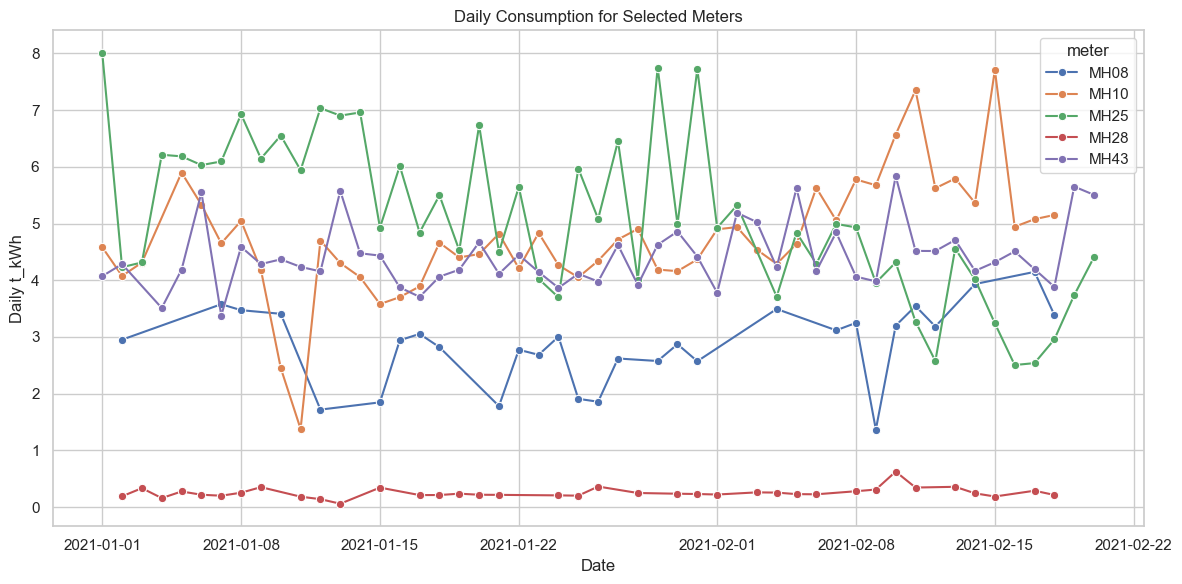

Selected meters: ['MH25', 'MH10', 'MH43', 'MH08', 'MH28']


In [16]:
daily_meter_consumption = (
    df.groupby(["meter", pd.Grouper(key=timestamp_column, freq="D")])[consumption_column]
    .sum()
    .reset_index(name="daily_t_kWh")
)

per_meter_daily_summary = (
    daily_meter_consumption.groupby("meter")
    .agg(
        days_observed=("daily_t_kWh", "size"),
        mean_daily_t_kWh=("daily_t_kWh", "mean"),
        median_daily_t_kWh=("daily_t_kWh", "median"),
        min_daily_t_kWh=("daily_t_kWh", "min"),
        max_daily_t_kWh=("daily_t_kWh", "max"),
        total_t_kWh=("daily_t_kWh", "sum"),
    )
    .sort_values("total_t_kWh", ascending=False)
)

display(per_meter_daily_summary.head(10))
display(per_meter_daily_summary.tail(10))

selected_meters = per_meter_daily_summary.head(3).index.tolist()
median_rank_meter = per_meter_daily_summary.iloc[len(per_meter_daily_summary) // 2].name
lowest_meter = per_meter_daily_summary.tail(1).index[0]
for meter_id in [median_rank_meter, lowest_meter]:
    if meter_id not in selected_meters:
        selected_meters.append(meter_id)

plot_data = daily_meter_consumption[daily_meter_consumption["meter"].isin(selected_meters)]
plt.figure(figsize=(12, 6))
sns.lineplot(data=plot_data, x=timestamp_column, y="daily_t_kWh", hue="meter", marker="o")
plt.title("Daily Consumption for Selected Meters")
plt.xlabel("Date")
plt.ylabel("Daily t_kWh")
plt.tight_layout()
plt.show()

print("Selected meters:", selected_meters)

### 12.6 Meter-Level Integrity Summary Objects

In [17]:
meter_integrity_summary = {
    "duplicate_meter_timestamp_rows": duplicate_meter_timestamp_rows,
    "duplicate_meter_timestamp_pairs": len(duplicate_meter_timestamp_pairs),
    "meters_checked": int(meter_coverage["meter"].nunique()),
    "meters_with_gaps_gt_3min": int((meter_coverage["gaps_gt_3min"] > 0).sum()),
    "total_gaps_gt_3min": int(meter_coverage["gaps_gt_3min"].sum()),
    "largest_gap": str(meter_coverage["largest_gap"].max()),
    "record_count_min": int(meter_coverage["record_count"].min()),
    "record_count_max": int(meter_coverage["record_count"].max()),
    "first_timestamp_min": meter_coverage["first_timestamp"].min(),
    "first_timestamp_max": meter_coverage["first_timestamp"].max(),
    "last_timestamp_min": meter_coverage["last_timestamp"].min(),
    "last_timestamp_max": meter_coverage["last_timestamp"].max(),
    "zero_voltage_frequency_masks_identical": bool(zero_voltage.equals(zero_frequency)),
    "selected_meters_for_daily_plot": selected_meters,
}

meter_integrity_summary

{'duplicate_meter_timestamp_rows': 0,
 'duplicate_meter_timestamp_pairs': 0,
 'meters_checked': 35,
 'meters_with_gaps_gt_3min': 35,
 'total_gaps_gt_3min': 261,
 'largest_gap': '29 days 00:03:00',
 'record_count_min': 6240,
 'record_count_max': 24000,
 'first_timestamp_min': Timestamp('2021-01-01 00:00:00'),
 'first_timestamp_max': Timestamp('2021-01-18 00:00:00'),
 'last_timestamp_min': Timestamp('2021-02-16 23:57:00'),
 'last_timestamp_max': Timestamp('2021-02-20 23:57:00'),
 'zero_voltage_frequency_masks_identical': True,
 'selected_meters_for_daily_plot': ['MH25', 'MH10', 'MH43', 'MH08', 'MH28']}

## 13. Targeted Data Integrity Investigation

This section follows up on the meter-level findings without deleting, imputing, or altering any source readings.

### 13.1 Source Documentation Notes

In [18]:
readme_candidates = []
if PROJECT_ROOT is not None:
    readme_candidates.append(PROJECT_ROOT / "dataverse_files" / "CEEW -  ReadMe.txt")
readme_candidates.append(DATA_PATH.parent / "CEEW -  ReadMe.txt")

README_PATH = next((path for path in readme_candidates if path.exists()), None)
if README_PATH is None:
    raise FileNotFoundError("Could not locate the CEEW ReadMe file beside the dataset.")

readme_text = README_PATH.read_text(encoding="utf-8", errors="replace")
print(f"ReadMe path: {README_PATH}")
print("Relevant documentation excerpts:")
for line in readme_text.splitlines():
    line_lower = line.lower()
    if any(term in line_lower for term in ["t_kwh", "voltage", "current", "freq", "three minute", "x_timestamp"]):
        print(line)

print("\nInterpretation from ReadMe:")
print("- t_kWh: electricity consumption")
print("- z_Avg Voltage (Volt): average voltage")
print("- z_Avg Current (Amp): average current")
print("- y_Freq (Hz): frequency")
print("- x_Timestamp: timestamp at every three-minute interval")
print("- Missing-value conventions: not documented in the inspected ReadMe")

ReadMe path: E:\MLOPS PROJECT\dataverse_files\CEEW -  ReadMe.txt
Relevant documentation excerpts:
                        by collecting high-frequency data from nearly 100 smart meters installed
- CEEW - Smart meter data Bareilly 2019.csv: A csv file that contains the information about electricity consumption (t_kWh), average voltage (z_Avg Voltage (Volt)),
                                             average current (z_Avg Current (Amp)), frequency (y_Freq (Hz)) of the smart meter(meter)  installed in Bareilly at every
                                             three minute interval (x_Timestamp) for the year 2019 in csv formats.
- CEEW - Smart meter data Bareilly 2020.csv: A csv file that contains the information about electricity consumption (t_kWh), average voltage (z_Avg Voltage (Volt)),
                                             average current (z_Avg Current (Amp)), frequency (y_Freq (Hz)) of the smart meter(meter)  installed in Bareilly at every
                            

### 13.2 Largest Timestamp Gaps with Exact Boundary Rows

In [19]:
investigation_sorted = df.sort_values(["meter", timestamp_column]).copy()
investigation_sorted["previous_timestamp"] = investigation_sorted.groupby("meter")[timestamp_column].shift()
investigation_sorted["timestamp_gap"] = investigation_sorted[timestamp_column] - investigation_sorted["previous_timestamp"]

largest_gap_rows = (
    investigation_sorted[investigation_sorted["timestamp_gap"] > expected_interval]
    .sort_values("timestamp_gap", ascending=False)
    .head(12)
)

selected_gap_summary = largest_gap_rows[[
    "meter", "previous_timestamp", timestamp_column, "timestamp_gap",
    "t_kWh", "z_Avg Voltage (Volt)", "z_Avg Current (Amp)", "y_Freq (Hz)"
]].rename(columns={timestamp_column: "next_timestamp"})

display(selected_gap_summary)

selected_gap_boundaries = []
for rank, (_, row) in enumerate(largest_gap_rows.iterrows(), start=1):
    meter_id = row["meter"]
    prev_ts = row["previous_timestamp"]
    next_ts = row[timestamp_column]
    boundary_rows = investigation_sorted[
        (investigation_sorted["meter"].eq(meter_id))
        & (investigation_sorted[timestamp_column].isin([prev_ts, next_ts]))
    ][[
        "meter", timestamp_column, "t_kWh", "z_Avg Voltage (Volt)",
        "z_Avg Current (Amp)", "y_Freq (Hz)", "timestamp_gap"
    ]].copy()
    boundary_rows.insert(0, "gap_rank", rank)
    selected_gap_boundaries.append(boundary_rows)

selected_gap_boundaries = pd.concat(selected_gap_boundaries, ignore_index=True)
display(selected_gap_boundaries)

,meter,previous_timestamp,next_timestamp,timestamp_gap,t_kWh,z_Avg Voltage (Volt),z_Avg Current (Amp),y_Freq (Hz)
448320,MH41,2021-01-15 23:57:00,2021-02-14,29 days 00:03:00,0.000000,253.120000,0.020000,50.050000
313440,MH26,2021-01-30 23:57:00,2021-02-09,9 days 00:03:00,0.000000,0.000000,0.000000,0.000000
207840,MH20,2021-01-08 23:57:00,2021-01-17,8 days 00:03:00,0.000000,0.000000,0.000000,0.000000
373920,MH33,2021-01-15 23:57:00,2021-01-24,8 days 00:03:00,0.003000,258.070000,0.250000,49.980000
382560,MH34,2021-01-25 23:57:00,2021-02-03,8 days 00:03:00,0.000000,0.000000,0.000000,0.000000
6720,MH01,2021-01-30 23:57:00,2021-02-07,7 days 00:03:00,0.000000,0.000000,0.000000,0.000000
380640,MH34,2021-01-05 23:57:00,2021-01-13,7 days 00:03:00,0.000000,0.000000,0.000000,0.000000
438720,MH39,2021-01-07 23:57:00,2021-01-15,7 days 00:03:00,0.000000,0.000000,0.000000,0.000000
214560,MH20,2021-02-09 23:57:00,2021-02-16,6 days 00:03:00,0.003000,263.910000,0.350000,50.040000
279840,MH24,2021-01-29 23:57:00,2021-02-05,6 days 00:03:00,0.000000,0.000000,0.000000,0.000000


,gap_rank,meter,x_Timestamp,t_kWh,z_Avg Voltage (Volt),z_Avg Current (Amp),y_Freq (Hz),timestamp_gap
0,1,MH41,2021-01-15 23:57:00,0.000000,256.560000,0.010000,50.070000,0 days 00:03:00
1,1,MH41,2021-02-14 00:00:00,0.000000,253.120000,0.020000,50.050000,29 days 00:03:00
2,2,MH26,2021-01-30 23:57:00,0.003000,268.630000,0.210000,49.950000,0 days 00:03:00
3,2,MH26,2021-02-09 00:00:00,0.000000,0.000000,0.000000,0.000000,9 days 00:03:00
4,3,MH20,2021-01-08 23:57:00,0.000000,0.000000,0.000000,0.000000,0 days 00:03:00
5,3,MH20,2021-01-17 00:00:00,0.000000,0.000000,0.000000,0.000000,8 days 00:03:00
6,4,MH33,2021-01-15 23:57:00,0.000000,0.000000,0.000000,0.000000,0 days 00:03:00
7,4,MH33,2021-01-24 00:00:00,0.003000,258.070000,0.250000,49.980000,8 days 00:03:00
8,5,MH34,2021-01-25 23:57:00,0.000000,0.000000,0.000000,0.000000,0 days 00:03:00
9,5,MH34,2021-02-03 00:00:00,0.000000,0.000000,0.000000,0.000000,8 days 00:03:00


### 13.3 Verifying Timestamp Gap and Zero-Run Calculations

In [20]:
print("Timestamp gap calculation:")
print("- Within each meter, rows are sorted by x_Timestamp.")
print("- timestamp_gap = current x_Timestamp - previous x_Timestamp for the same meter.")
print("- A gap is flagged when timestamp_gap > 3 minutes.")
print("- The first row for each meter has no previous timestamp and is not counted as a gap.")

print("\nZero-run duration calculation:")
print("- A run of N contiguous 3-minute readings has elapsed time from first to last timestamp of (N - 1) * 3 minutes.")
print("- The measurement window covered by those N reading slots is N * 3 minutes.")
print("- The original zero-run table counted consecutive observed zero records in row order; the verified table below also breaks runs at timestamp gaps.")

def contiguous_zero_runs_by_meter(frame: pd.DataFrame, value_column: str) -> pd.DataFrame:
    work = frame[["meter", timestamp_column, value_column]].sort_values(["meter", timestamp_column]).copy()
    work["previous_timestamp"] = work.groupby("meter")[timestamp_column].shift()
    work["timestamp_gap"] = work[timestamp_column] - work["previous_timestamp"]
    work["is_zero"] = work[value_column].eq(0)
    starts_new_run = (
        work["meter"].ne(work["meter"].shift())
        | work["is_zero"].ne(work["is_zero"].shift())
        | work["timestamp_gap"].ne(expected_interval)
    )
    work["run_id"] = starts_new_run.cumsum()
    runs = (
        work[work["is_zero"]]
        .groupby(["meter", "run_id"])
        .agg(
            run_length_records=("is_zero", "size"),
            start_timestamp=(timestamp_column, "min"),
            end_timestamp=(timestamp_column, "max"),
        )
        .reset_index()
    )
    runs["elapsed_minutes_first_to_last"] = (
        runs["end_timestamp"] - runs["start_timestamp"]
    ).dt.total_seconds() / 60
    runs["covered_interval_minutes"] = runs["run_length_records"] * 3
    return runs.sort_values("run_length_records", ascending=False).reset_index(drop=True)

contiguous_zero_run_summaries = {
    column: contiguous_zero_runs_by_meter(df, column)
    for column in ["t_kWh", "z_Avg Voltage (Volt)", "y_Freq (Hz)"]
}

for column, summary in contiguous_zero_run_summaries.items():
    print(f"Gap-aware contiguous zero runs for {column}:")
    display(summary.head(10))

Timestamp gap calculation:
- Within each meter, rows are sorted by x_Timestamp.
- timestamp_gap = current x_Timestamp - previous x_Timestamp for the same meter.
- A gap is flagged when timestamp_gap > 3 minutes.
- The first row for each meter has no previous timestamp and is not counted as a gap.

Zero-run duration calculation:
- A run of N contiguous 3-minute readings has elapsed time from first to last timestamp of (N - 1) * 3 minutes.
- The measurement window covered by those N reading slots is N * 3 minutes.
- The original zero-run table counted consecutive observed zero records in row order; the verified table below also breaks runs at timestamp gaps.


Gap-aware contiguous zero runs for t_kWh:


,meter,run_id,run_length_records,start_timestamp,end_timestamp,elapsed_minutes_first_to_last,covered_interval_minutes
0,MH28,23764,457,2021-01-12 19:12:00,2021-01-13 18:00:00,1368.000000,1371
1,MH33,32359,236,2021-01-24 16:12:00,2021-01-25 03:57:00,705.000000,708
2,MH30,31893,225,2021-02-16 19:24:00,2021-02-17 06:36:00,672.000000,675
3,MH30,31895,224,2021-02-17 07:15:00,2021-02-17 18:24:00,669.000000,672
4,MH18,15228,221,2021-01-26 16:36:00,2021-01-27 03:36:00,660.000000,663
5,MH01,350,221,2021-01-13 17:00:00,2021-01-14 04:00:00,660.000000,663
6,MH24,19207,218,2021-01-11 17:57:00,2021-01-12 04:48:00,651.000000,654
7,MH08,2518,212,2021-01-25 17:30:00,2021-01-26 04:03:00,633.000000,636
8,MH01,1077,203,2021-02-12 17:30:00,2021-02-13 03:36:00,606.000000,609
9,MH06,2087,201,2021-02-09 16:54:00,2021-02-10 02:54:00,600.000000,603


Gap-aware contiguous zero runs for z_Avg Voltage (Volt):


,meter,run_id,run_length_records,start_timestamp,end_timestamp,elapsed_minutes_first_to_last,covered_interval_minutes
0,MH33,4797,236,2021-01-24 16:12:00,2021-01-25 03:57:00,705.000000,708
1,MH01,47,221,2021-01-13 17:00:00,2021-01-14 04:00:00,660.000000,663
2,MH18,2127,218,2021-01-26 16:45:00,2021-01-27 03:36:00,651.000000,654
3,MH24,2746,218,2021-01-11 17:57:00,2021-01-12 04:48:00,651.000000,654
4,MH08,778,212,2021-01-25 17:30:00,2021-01-26 04:03:00,633.000000,636
5,MH01,119,203,2021-02-12 17:30:00,2021-02-13 03:36:00,606.000000,609
6,MH08,846,201,2021-02-09 16:51:00,2021-02-10 02:51:00,600.000000,603
7,MH06,483,201,2021-02-09 16:54:00,2021-02-10 02:54:00,600.000000,603
8,MH08,748,200,2021-01-21 16:24:00,2021-01-22 02:21:00,597.000000,600
9,MH07,584,199,2021-01-21 16:24:00,2021-01-22 02:18:00,594.000000,597


Gap-aware contiguous zero runs for y_Freq (Hz):


,meter,run_id,run_length_records,start_timestamp,end_timestamp,elapsed_minutes_first_to_last,covered_interval_minutes
0,MH33,4797,236,2021-01-24 16:12:00,2021-01-25 03:57:00,705.000000,708
1,MH01,47,221,2021-01-13 17:00:00,2021-01-14 04:00:00,660.000000,663
2,MH18,2127,218,2021-01-26 16:45:00,2021-01-27 03:36:00,651.000000,654
3,MH24,2746,218,2021-01-11 17:57:00,2021-01-12 04:48:00,651.000000,654
4,MH08,778,212,2021-01-25 17:30:00,2021-01-26 04:03:00,633.000000,636
5,MH01,119,203,2021-02-12 17:30:00,2021-02-13 03:36:00,606.000000,609
6,MH08,846,201,2021-02-09 16:51:00,2021-02-10 02:51:00,600.000000,603
7,MH06,483,201,2021-02-09 16:54:00,2021-02-10 02:54:00,600.000000,603
8,MH08,748,200,2021-01-21 16:24:00,2021-01-22 02:21:00,597.000000,600
9,MH07,584,199,2021-01-21 16:24:00,2021-01-22 02:18:00,594.000000,597


### 13.4 Zero Voltage and Frequency with Non-Zero Consumption

In [21]:
zero_vf_nonzero_consumption_mask = (
    df["z_Avg Voltage (Volt)"].eq(0)
    & df["y_Freq (Hz)"].eq(0)
    & df["t_kWh"].ne(0)
)
zero_vf_nonzero_consumption = df.loc[zero_vf_nonzero_consumption_mask].sort_values(["meter", timestamp_column]).copy()

print(f"Records with zero voltage, zero frequency, and non-zero t_kWh: {len(zero_vf_nonzero_consumption):,}")
display(zero_vf_nonzero_consumption.groupby("meter").size().sort_values(ascending=False).to_frame("record_count"))
display(zero_vf_nonzero_consumption[["meter", timestamp_column, "t_kWh", "z_Avg Voltage (Volt)", "z_Avg Current (Amp)", "y_Freq (Hz)"]].head(20))

def nearby_records(frame: pd.DataFrame, events: pd.DataFrame, minutes: int = 6, max_events: int = 10) -> pd.DataFrame:
    windows = []
    sorted_frame = frame.sort_values(["meter", timestamp_column])
    for event_number, (_, event) in enumerate(events.head(max_events).iterrows(), start=1):
        meter_id = event["meter"]
        center = event[timestamp_column]
        window = sorted_frame[
            (sorted_frame["meter"].eq(meter_id))
            & (sorted_frame[timestamp_column].between(center - pd.Timedelta(minutes=minutes), center + pd.Timedelta(minutes=minutes)))
        ][["meter", timestamp_column, "t_kWh", "z_Avg Voltage (Volt)", "z_Avg Current (Amp)", "y_Freq (Hz)"]].copy()
        window.insert(0, "event_number", event_number)
        window.insert(2, "center_timestamp", center)
        windows.append(window)
    return pd.concat(windows, ignore_index=True) if windows else pd.DataFrame()

zero_vf_nonzero_context = nearby_records(df, zero_vf_nonzero_consumption, minutes=6, max_events=10)
display(zero_vf_nonzero_context)

Records with zero voltage, zero frequency, and non-zero t_kWh: 45


,record_count
meter,
MH36,6
MH25,3
MH45,3
MH27,3
MH10,3
MH42,3
MH43,3
MH03,2
MH01,2


,meter,x_Timestamp,t_kWh,z_Avg Voltage (Volt),z_Avg Current (Amp),y_Freq (Hz)
7334,MH01,2021-02-08 06:42:00,0.002000,0.000000,0.000000,0.000000
11449,MH01,2021-02-17 20:27:00,0.001000,0.000000,0.000000,0.000000
16198,MH03,2021-01-11 17:54:00,0.001000,0.000000,0.000000,0.000000
24678,MH03,2021-01-29 09:54:00,0.003000,0.000000,0.000000,0.000000
42890,MH06,2021-02-02 08:30:00,0.001000,0.000000,0.000000,0.000000
44403,MH06,2021-02-06 12:09:00,0.004000,0.000000,0.000000,0.000000
99730,MH10,2021-01-14 18:30:00,0.001000,0.000000,0.000000,0.000000
107281,MH10,2021-01-30 12:03:00,0.001000,0.000000,0.000000,0.000000
108493,MH10,2021-02-02 00:39:00,0.001000,0.000000,0.000000,0.000000
128893,MH11,2021-01-27 12:39:00,0.001000,0.000000,0.000000,0.000000


,event_number,meter,center_timestamp,x_Timestamp,t_kWh,z_Avg Voltage (Volt),z_Avg Current (Amp),y_Freq (Hz)
0,1,MH01,2021-02-08 06:42:00,2021-02-08 06:36:00,0.062000,265.490000,4.690000,49.920000
1,1,MH01,2021-02-08 06:42:00,2021-02-08 06:39:00,0.062000,265.730000,4.690000,49.890000
2,1,MH01,2021-02-08 06:42:00,2021-02-08 06:42:00,0.002000,0.000000,0.000000,0.000000
3,1,MH01,2021-02-08 06:42:00,2021-02-08 06:45:00,0.000000,0.000000,0.000000,0.000000
4,1,MH01,2021-02-08 06:42:00,2021-02-08 06:48:00,0.000000,0.000000,0.000000,0.000000
5,2,MH01,2021-02-17 20:27:00,2021-02-17 20:21:00,0.007000,270.030000,1.170000,50.020000
6,2,MH01,2021-02-17 20:27:00,2021-02-17 20:24:00,0.006000,270.060000,1.320000,50.060000
7,2,MH01,2021-02-17 20:27:00,2021-02-17 20:27:00,0.001000,0.000000,0.000000,0.000000
8,2,MH01,2021-02-17 20:27:00,2021-02-17 20:30:00,0.006000,267.580000,2.460000,49.960000
9,2,MH01,2021-02-17 20:27:00,2021-02-17 20:33:00,0.008000,268.460000,1.550000,49.930000


### 13.5 Largest Voltage and Frequency Values with Surrounding Records

In [22]:
largest_voltage_records = df.nlargest(10, "z_Avg Voltage (Volt)")[[
    "meter", timestamp_column, "t_kWh", "z_Avg Voltage (Volt)", "z_Avg Current (Amp)", "y_Freq (Hz)"
]]
largest_frequency_records = df.nlargest(10, "y_Freq (Hz)")[[
    "meter", timestamp_column, "t_kWh", "z_Avg Voltage (Volt)", "z_Avg Current (Amp)", "y_Freq (Hz)"
]]

print("Largest voltage readings:")
display(largest_voltage_records)
print("Largest frequency readings:")
display(largest_frequency_records)

voltage_context = nearby_records(df, largest_voltage_records, minutes=6, max_events=5)
frequency_context = nearby_records(df, largest_frequency_records, minutes=6, max_events=5)

print("Surrounding records for top voltage readings:")
display(voltage_context)
print("Surrounding records for top frequency readings:")
display(frequency_context)

Largest voltage readings:


,meter,x_Timestamp,t_kWh,z_Avg Voltage (Volt),z_Avg Current (Amp),y_Freq (Hz)
427524,MH37,2021-01-26 16:12:00,0.009000,654.730000,0.870000,49.980000
427531,MH37,2021-01-26 16:33:00,0.005000,654.390000,0.480000,50.020000
426726,MH37,2021-01-25 00:18:00,0.007000,653.970000,0.600000,50.040000
427532,MH37,2021-01-26 16:36:00,0.006000,652.350000,0.490000,50.010000
427533,MH37,2021-01-26 16:39:00,0.005000,651.230000,0.480000,50.000000
426446,MH37,2021-01-24 10:18:00,0.000000,649.070000,0.980000,49.970000
427518,MH37,2021-01-26 15:54:00,0.006000,648.770000,0.510000,50.020000
432288,MH37,2021-02-05 14:24:00,0.003000,647.470000,1.010000,50.050000
410780,MH36,2021-02-09 19:00:00,0.001000,614.290000,2.470000,49.960000
427508,MH37,2021-01-26 15:24:00,0.007000,602.950000,0.490000,50.100000


Largest frequency readings:


,meter,x_Timestamp,t_kWh,z_Avg Voltage (Volt),z_Avg Current (Amp),y_Freq (Hz)
548546,MH47,2021-02-07 19:18:00,0.000000,1.690000,0.000000,74.760000
374675,MH33,2021-01-25 13:45:00,0.001000,1.010000,0.330000,72.040000
375218,MH33,2021-01-27 16:54:00,0.003000,224.900000,0.190000,70.630000
527384,MH46,2021-01-13 17:12:00,0.000000,221.820000,0.060000,66.080000
56230,MH07,2021-01-23 03:30:00,0.004000,272.470000,0.480000,64.080000
367408,MH31,2021-01-31 10:24:00,0.001000,179.140000,0.460000,57.290000
469568,MH42,2021-02-08 06:24:00,0.030000,243.090000,2.980000,55.710000
468615,MH42,2021-02-06 06:45:00,0.001000,204.840000,0.180000,55.700000
324233,MH27,2021-02-10 11:39:00,0.002000,192.920000,0.700000,54.810000
362753,MH31,2021-01-13 17:39:00,0.002000,257.920000,0.250000,54.570000


Surrounding records for top voltage readings:


,event_number,meter,center_timestamp,x_Timestamp,t_kWh,z_Avg Voltage (Volt),z_Avg Current (Amp),y_Freq (Hz)
0,1,MH37,2021-01-26 16:12:00,2021-01-26 16:06:00,0.000000,0.000000,0.000000,0.000000
1,1,MH37,2021-01-26 16:12:00,2021-01-26 16:09:00,0.000000,94.830000,0.830000,49.980000
2,1,MH37,2021-01-26 16:12:00,2021-01-26 16:12:00,0.009000,654.730000,0.870000,49.980000
3,1,MH37,2021-01-26 16:12:00,2021-01-26 16:15:00,0.006000,44.050000,0.580000,49.960000
4,1,MH37,2021-01-26 16:12:00,2021-01-26 16:18:00,0.006000,43.890000,0.510000,49.990000
5,2,MH37,2021-01-26 16:33:00,2021-01-26 16:27:00,0.006000,42.930000,0.510000,49.970000
6,2,MH37,2021-01-26 16:33:00,2021-01-26 16:30:00,0.006000,38.660000,0.490000,50.000000
7,2,MH37,2021-01-26 16:33:00,2021-01-26 16:33:00,0.005000,654.390000,0.480000,50.020000
8,2,MH37,2021-01-26 16:33:00,2021-01-26 16:36:00,0.006000,652.350000,0.490000,50.010000
9,2,MH37,2021-01-26 16:33:00,2021-01-26 16:39:00,0.005000,651.230000,0.480000,50.000000


Surrounding records for top frequency readings:


,event_number,meter,center_timestamp,x_Timestamp,t_kWh,z_Avg Voltage (Volt),z_Avg Current (Amp),y_Freq (Hz)
0,1,MH47,2021-02-07 19:18:00,2021-02-07 19:12:00,0.001000,252.240000,0.050000,49.930000
1,1,MH47,2021-02-07 19:18:00,2021-02-07 19:15:00,0.000000,252.150000,0.050000,49.900000
2,1,MH47,2021-02-07 19:18:00,2021-02-07 19:18:00,0.000000,1.690000,0.000000,74.760000
3,1,MH47,2021-02-07 19:18:00,2021-02-07 19:21:00,0.000000,0.000000,0.000000,0.000000
4,1,MH47,2021-02-07 19:18:00,2021-02-07 19:24:00,0.000000,0.000000,0.000000,0.000000
5,2,MH33,2021-01-25 13:45:00,2021-01-25 13:39:00,0.007000,257.200000,0.720000,49.960000
6,2,MH33,2021-01-25 13:45:00,2021-01-25 13:42:00,0.007000,258.220000,0.730000,50.010000
7,2,MH33,2021-01-25 13:45:00,2021-01-25 13:45:00,0.001000,1.010000,0.330000,72.040000
8,2,MH33,2021-01-25 13:45:00,2021-01-25 13:48:00,0.000000,0.000000,0.000000,0.000000
9,2,MH33,2021-01-25 13:45:00,2021-01-25 13:51:00,0.000000,0.000000,0.000000,0.000000


### 13.6 Confirmed Patterns vs Hypotheses

In [23]:
targeted_investigation_summary = {
    "readme_interval": "three minutes",
    "readme_missing_value_convention": "not documented in inspected ReadMe",
    "largest_gap_meter": selected_gap_summary.iloc[0]["meter"],
    "largest_gap_previous_timestamp": selected_gap_summary.iloc[0]["previous_timestamp"],
    "largest_gap_next_timestamp": selected_gap_summary.iloc[0]["next_timestamp"],
    "largest_gap": str(selected_gap_summary.iloc[0]["timestamp_gap"]),
    "zero_vf_nonzero_consumption_records": int(len(zero_vf_nonzero_consumption)),
    "max_voltage": float(df["z_Avg Voltage (Volt)"].max()),
    "max_voltage_meter": largest_voltage_records.iloc[0]["meter"],
    "max_voltage_timestamp": largest_voltage_records.iloc[0][timestamp_column],
    "max_frequency": float(df["y_Freq (Hz)"].max()),
    "max_frequency_meter": largest_frequency_records.iloc[0]["meter"],
    "max_frequency_timestamp": largest_frequency_records.iloc[0][timestamp_column],
    "confirmed_patterns": [
        "ReadMe defines the primary file fields and states a three-minute interval.",
        "No missing-value convention was found in the inspected ReadMe.",
        "The largest observed same-meter timestamp gap is MH41 from 2021-01-15 23:57:00 to 2021-02-14 00:00:00.",
        "There are 45 records where voltage and frequency are both zero while t_kWh is non-zero.",
        "The top voltage values are concentrated in meter MH37 in this file.",
        "The top frequency values occur across multiple meters and often near low/zero voltage or following normal-frequency rows.",
    ],
    "hypotheses_to_validate": [
        "Large gaps may reflect meter coverage windows, communication/data extraction gaps, outages, or cleaned-source filtering.",
        "Zero voltage/frequency with non-zero t_kWh may reflect interval accumulation semantics, lag between fields, meter behavior, or data-quality artifacts.",
        "Extreme voltage/frequency values may be true events, device artifacts, scaling issues, or transient measurement errors.",
    ],
}

targeted_investigation_summary

{'readme_interval': 'three minutes',
 'readme_missing_value_convention': 'not documented in inspected ReadMe',
 'largest_gap_meter': 'MH41',
 'largest_gap_previous_timestamp': Timestamp('2021-01-15 23:57:00'),
 'largest_gap_next_timestamp': Timestamp('2021-02-14 00:00:00'),
 'largest_gap': '29 days 00:03:00',
 'zero_vf_nonzero_consumption_records': 45,
 'max_voltage': 654.73,
 'max_voltage_meter': 'MH37',
 'max_voltage_timestamp': Timestamp('2021-01-26 16:12:00'),
 'max_frequency': 74.76,
 'max_frequency_meter': 'MH47',
 'max_frequency_timestamp': Timestamp('2021-02-07 19:18:00'),
 'confirmed_patterns': ['ReadMe defines the primary file fields and states a three-minute interval.',
  'No missing-value convention was found in the inspected ReadMe.',
  'The largest observed same-meter timestamp gap is MH41 from 2021-01-15 23:57:00 to 2021-02-14 00:00:00.',
  'There are 45 records where voltage and frequency are both zero while t_kWh is non-zero.',
  'The top voltage values are concentrate